# 15 · Design patterns 1 and 2: prompt chaining and routing
Level L3 · Part 3 · core · ~30 min · builds on 01, 04

## Goal
Build two patterns as small graphs. **Prompt chaining** runs fixed steps in order, each step reading the last one's output. **Routing**
uses one model call to classify a message, then sends it to one of several branches. Each pattern is a few nodes, and the model's
decision sits in one visible place.

## Why it matters
A single prompt that does everything is hard to check: when it fails, you cannot tell which part went wrong. A customer message also mixes
jobs, and a refund needs different handling from a status question. Patterns split the work so each part can be tested, and a wrong route
is visible in the graph.

| One big prompt | Chaining | Routing |
|---|---|---|
| One answer; a failure hides in it | Each step has its own output you can check | One classification; a wrong branch is visible |
| Long and fragile | Short steps, each with one job | The branches stay small |
| Cost is fixed and unclear | Cost is the number of steps, counted | Only the branch that runs costs its calls |

**What it makes easy:** a pipeline you can test one step at a time. **When you don't need it:** a single question with one answer.

## The idea
**Prompt chaining**: step A's output is step B's input. The steps are known in advance, so the graph is a line. **Routing**: a classifier
step returns a label, and a conditional edge sends the message to the branch for that label. The model decides the label; the code decides
what each label does.

## Picture
Two drawing helpers from `graph_view.py` are used below. `show_mermaid` draws a flowchart from text, and `show_graph` draws a compiled
LangGraph app and colours its model nodes. Both fetch the picture from the internet; offline they print the text instead.

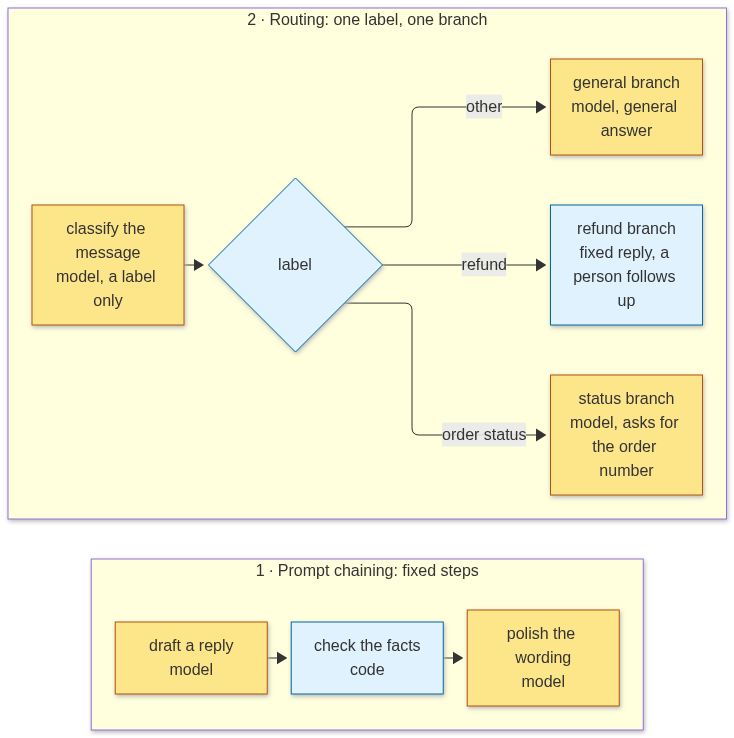

In [1]:
import sys; sys.path.insert(0, "../../..")  # the topic folder: llm_setup.py, graph_view.py and tut_env.py live there

from graph_view import show_mermaid

show_mermaid("""
flowchart LR
  subgraph CH["1 · Prompt chaining: fixed steps"]
    a["draft a reply<br/>model"] --> b["check the facts<br/>code"] --> c["polish the wording<br/>model"]
  end
  subgraph RT["2 · Routing: one label, one branch"]
    m["classify the message<br/>model, a label only"] --> r{"label"}
    r -->|refund| x["refund branch<br/>fixed reply, a person follows up"]
    r -->|order status| y["status branch<br/>model, asks for the order number"]
    r -->|other| z["general branch<br/>model, general answer"]
  end
  classDef model fill:#fde68a,stroke:#b45309
  classDef code fill:#e0f2fe,stroke:#0369a1
  class a,c,m,y,z model
  class b,r,x code
""")

## Step by step

**Step 1 · setup (one model for the lesson).** The key is read from `.env`, never typed here. `llm_replay` is the course's recorder: it
saves each model answer the first time and replays it later, so the notebook runs offline with no key. `get_llm()` is the shared model
setup (Gemini on Vertex AI).

In [2]:
import llm_replay
llm_replay.start("15_chaining-and-routing")

from typing import Literal
from typing_extensions import TypedDict
from langgraph.graph import END, START, StateGraph
from llm_setup import get_llm
from graph_view import show_graph

llm = get_llm()

LLM mode: replay (15_chaining-and-routing.yaml)


Gemini on Vertex AI · API key loaded: True


**Step 2 · prompt chaining: draft, check, polish (2 model calls).** The draft is written from the customer's message. The check is code: it
looks for the order number the customer gave, and for a promise the desk may not make. The polish is a model step that changes only the
wording, and it is given the checked facts, so it cannot add new ones.

In [3]:
class ChainState(TypedDict):
    message: str
    draft: str
    problems: list
    reply: str


def draft(state: ChainState) -> dict:
    return {"draft": llm.invoke("Draft a two-sentence support reply to this customer. Do not promise a refund. You cannot look "
                                "anything up, so do not say you have checked or started anything.\n\n"
                                f"Customer: {state['message']}").text}


def check(state: ChainState) -> dict:
    problems = []
    order = [w for w in state["message"].split() if w.strip("?.,").isdigit() and len(w.strip("?.,")) == 4]
    for number in order:
        if number.strip("?.,") not in state["draft"]:
            problems.append(f"the draft does not mention order {number}")
    if "refund is approved" in state["draft"].lower():
        problems.append("the draft promises a refund; a person approves refunds")
    return {"problems": problems}

The polish step, the graph and one run come next.

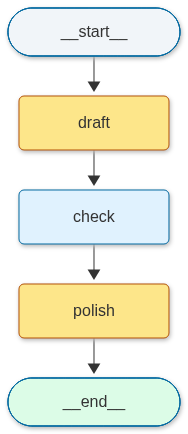

problems found by the check: []
reply: I am so sorry to hear that your parcel for order 1093 hasn't arrived as expected. Could you please share your current shipping address with me? I would like to look into this right away and investigate the status of your delivery for you.


In [4]:
def polish(state: ChainState) -> dict:
    fixes = f"Fix these problems: {state['problems']}" if state["problems"] else "The facts are right."
    return {"reply": llm.invoke(f"Rewrite this reply for warmth, keeping every fact. {fixes} Return one version only, with no options "
                                f"and no preamble.\n\nReply: {state['draft']}").text}


chain = StateGraph(ChainState)
chain.add_node("draft", draft)
chain.add_node("check", check)
chain.add_node("polish", polish)
chain.add_edge(START, "draft").add_edge("draft", "check").add_edge("check", "polish").add_edge("polish", END)
chain_app = chain.compile()
show_graph(chain_app, model_nodes=("draft", "polish"))
out = chain_app.invoke({"message": "My parcel for order 1093 never came. Can I get a refund?", "draft": "", "problems": [], "reply": ""})
print("problems found by the check:", out["problems"])
print("reply:", out["reply"])

**Step 3 · routing: one label, one branch (one classify call per message, then one branch call).** The classifier answers with one of
three labels. It returns a label only, and the code checks that the label is one it knows. Each branch has its own code: the status and
general branches call the model, and the refund branch returns a fixed reply.

In [5]:
LABELS = ("refund", "order_status", "other")


class RouteState(TypedDict):
    message: str
    label: str
    reply: str


def classify(state: RouteState) -> dict:
    answer = llm.invoke("Classify the customer message as exactly one word: refund, order_status, or other.\n\n"
                        f"Message: {state['message']}").text.strip().lower()
    label = answer if answer in LABELS else "other"  # an unknown label goes to the general branch
    return {"label": label}

The three branches come next. Each one answers in its own way, so the refund branch can never answer like a status lookup.

In [6]:
def refund_branch(state: RouteState) -> dict:
    return {"reply": "I have passed your refund request to a person on our team, who will reply within one working day."}


def status_branch(state: RouteState) -> dict:
    return {"reply": llm.invoke("Answer in one sentence. You cannot look up orders here, so ask for the order number if it is "
                                "missing, and do not say you have found anything.\n\n"
                                f"Customer: {state['message']}").text}


def general_branch(state: RouteState) -> dict:
    return {"reply": llm.invoke(f"Answer briefly from general support knowledge, and say when you are not sure.\n\n"
                                f"Customer: {state['message']}").text}

Next the router function and the graph: the router reads the label and names the branch.

In [7]:
def route(state: RouteState) -> Literal["refund_branch", "status_branch", "general_branch"]:
    return {"refund": "refund_branch", "order_status": "status_branch", "other": "general_branch"}[state["label"]]


rt = StateGraph(RouteState)
for name, fn in [("classify", classify), ("refund_branch", refund_branch), ("status_branch", status_branch),
                 ("general_branch", general_branch)]:
    rt.add_node(name, fn)
rt.add_edge(START, "classify")
rt.add_conditional_edges("classify", route, {"refund_branch": "refund_branch", "status_branch": "status_branch",
                                             "general_branch": "general_branch"})
rt.add_edge("refund_branch", END).add_edge("status_branch", END).add_edge("general_branch", END)
route_app = rt.compile()

Last, the graph is drawn and run on two messages.

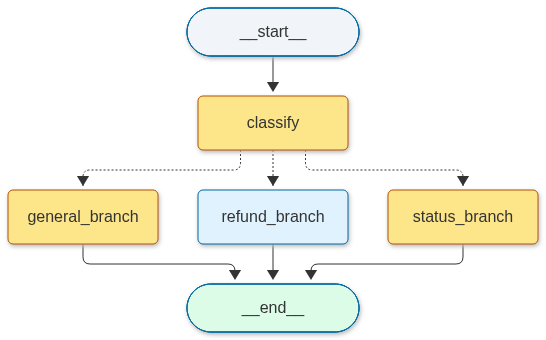

'Where is my order 1093?' → order_status: I do not have access to your order details, so please provide your order number if it was not included in your
'I want my money back for the jacket.' → refund: I have passed your refund request to a person on our team, who will reply within one working day.


In [8]:
show_graph(route_app, model_nodes=("classify", "status_branch", "general_branch"))
for message in ("Where is my order 1093?", "I want my money back for the jacket."):
    result = route_app.invoke({"message": message, "label": "", "reply": ""})
    print(f"{message!r} → {result['label']}: {result['reply'][:110]}")
llm_replay.stop()  # the last model call of this lesson

## At work
- Chaining is the first pattern most teams use. A check between two model steps is where a team catches a wrong fact before a customer does
  → lesson 22 (eval depth: error analysis and graders).
- A route is cheap when it is one label. Teams route easy messages to a small model and keep the large one for the hard branch → lesson 33
  (cost and latency).
- An unknown label must go somewhere safe. Here it goes to the general branch, and a person handles the refund branch; a paused approval
  that survives a restart is lesson 35 (durable execution).

## What just happened
- The check found 0 problems in the chained reply, so the polish step was told "The facts are right."
- "Where is my order 1093?" was routed to `order_status`: one classify call and one status-branch call.
- "I want my money back for the jacket." was routed to `refund`: one classify call, and the branch returned its fixed reply.
- The lesson makes 5 model calls in total: 2 for the chain, 2 for the classifier and 1 for the status branch.

## Common mistakes
1. **A classifier that returns a sentence.** If the code skips the label check, the router has no branch for the sentence and fails.
   Ask for one word, check it, and send anything else to the general branch.
2. **A polish step that adds facts.** Give the polish step the checked facts and say to keep every fact.
3. **A check that only reads the model's words.** Check the facts against the input: the order number the customer gave is the one that must appear.

In [9]:
try:
    route({"label": "I think refund"})  # the label was not cleaned: no branch has this key
except Exception as error:
    print(type(error).__name__, str(error).splitlines()[0])

KeyError 'I think refund'


## Try it
Write `route_label(answer)` that returns the answer if it is one of `refund`, `order_status` or `other`, and `"other"` otherwise. Test it on
`"refund"` and on `"I think refund"`. No model call is needed.

In [10]:
# your code here

**Answer** — try it first, then expand the hidden cell below.

In [11]:
def route_label(answer: str) -> str:
    return answer if answer in ("refund", "order_status", "other") else "other"


print(route_label("refund"), route_label("I think refund"))  # refund other

refund other


## Key terms
- **Prompt chaining** — fixed steps run in order, each reading the output of the step before it.
- **Routing** — one classification step returns a label, and the graph sends the message to the branch for that label.
- **Conditional edge** — a graph edge whose target is chosen by a function that reads the state.
- **Label** — the short answer a classifier returns, checked by code before it is used to route.

## Recap
- Prompt chaining is a fixed line of steps, where each output is checked or reshaped before the next step.
- Routing is one classification, then one branch. An unknown label goes somewhere safe.
- Both are graphs with few nodes, and the drawing shows where the model decides.

**Interview:** "A support message can be a refund or a status question. How do you handle it?" Strong answer: "A classifier returns one label
that the code checks; each label has its own branch, and refunds go to a person. If the label is unknown, the message goes to the general branch."